### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [2]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco
from scipy.interpolate import interp1d
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

# statsmodels is a Python package that provides a complement to scipy for statistical computations
# mainly for timeseries analysis
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Nelson Siegel Svensson Model
from nelson_siegel_svensson import NelsonSiegelCurve, NelsonSiegelSvenssonCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols, calibrate_nss_ols

#-------------------------------------------------------------------------------------------------------------
# SABR(Stochastic Alpha, Beta, Rho)
from pysabr import Hagan2002LognormalSABR
from pysabr import Hagan2002NormalSABR
from pysabr.helpers import year_frac_from_maturity_label

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

#-------------------------------------------------------------------------------------------------------------
# Quantlib package
from QuantLib import *

#-------------------------------------------------------------------------------------------------------------
# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

import itertools

# ARCH Toolbox
from arch import arch_model

Module "zipline.assets" not found; mutltipliers will not be applied to position notionals.


# A. Manual Calculation for CDS

### Credit Curve

In part two of this credit lab, we'll extend the understanding from the earlier lab to model hazard rates and fix missing values. Table below shows the term structure of credit spreads for two reference entities: Wells Fargo (WFC) - a highly rated institution and Clear Channel Communication (CCMO) - a highly leveraged entity.

|Maturity|WFC|CCMO|Z(0,T)|
| --- | --- | --- |---|
|1Y|50|751|0.97|
|2Y|77|1194|0.94|
|3Y|94|1874|0.92|
|5Y|125|4156|0.86|
|7Y|133|6083|0.81|

The objective here is to bootstrap implied survival probabilities along with the term structure of hazard rate for
- WFC bank with recovery rate of 50%
- CCMO corporation with recovery rate of 10%

Similar to the previous lab module, we'll then study the effect of an increase in recovery rate on implied survival probabilities for different values of RR.

In [3]:
# subsume list of inputs into a dataframe
cds = pd.DataFrame({'Maturity' : [1,2,3,5,7],
                    'WFC' : [50,77,94,125,133],
                    'CCMO' : [751,1194,1874,4156,6083],
                    'Df' :[0.97,0.94,0.92,0.86,0.81]})

cds         

,Maturity,WFC,CCMO,Df
0,1,50,751,0.9700
1,2,77,1194,0.9400
2,3,94,1874,0.9200
3,5,125,4156,0.8600
4,7,133,6083,0.8100


## Interpolation

Given the missing data points in the CDS table, we'll have to perform interpolation to derive the missing tenor and spreads before we proceed with our analysis.

### Discount Factors

For discounting factors, we'll do a log-linear interpolation for $\tau_i < \tau < \tau_{i+1}$

$$ CDS(\tau) = \frac{\tau - \tau_i}{\tau_{i+1} - \tau_i} CDS_{i+1} + \frac{\tau_{i+1} - \tau}{\tau_{i+1} - \tau_i} CDS_{i}$$


We'll now create a User Defined Function (UDF) in Python to derive the discount factors.

In [4]:
def get_discount_factors(maturity,discout_factor,tenor):
    max_time_index = len(maturity) - 1
    if tenor == 0:
        Df =1
    elif (tenor > 0) & (tenor < maturity[0]):
        Df = discout_factor[0]
    elif tenor >= maturity[max_time_index]:
         Df = discout_factor[max_time_index]
    
    
    for i in range(0, max_time_index):
        if (tenor >= maturity[i]) & (tenor < maturity[i+1]):
            term_1 = ((tenor - maturity[i])/(maturity[i+1] - maturity[i]))*np.log(discout_factor[i+1])
            term_2 = ((maturity[i+1]-tenor)/(maturity[i+1] - maturity[i]))*np.log(discout_factor[i])
            lnDf = term_1 + term_2
            Df = np.exp(lnDf)
    
    return Df       

In [5]:
t = np.arange(0,8)
Df = np.zeros(len(t))

for i in range(len(t)):
    Df[i] = get_discount_factors(cds['Maturity'],cds['Df'], t[i])

### Credit Spreads

For credit spreads (or equally hazard rates), a linear interpolation is done either using the below formulation or by applying the method of your choice.

$$ CDS(\tau) = \frac{\tau - \tau_i}{\tau_{i+1} - \tau_i} CDS_{i+1} + \frac{\tau_{i+1} - \tau}{\tau_{i+1} - \tau_i} CDS_{i}$$

In this case, we'll leverage the power of NumPy by directly applying the interp methods for interpolation of spread values.

In [6]:
# interpolation WFC spreads
wfc = np.interp(x = t,xp= cds.Maturity, fp = cds.WFC)

# set spreads to zero at t=0
wfc[0] = 0

# interpolation CCMO spreads
ccmo = np.interp(t,cds.Maturity,cds.CCMO)

# set spreads to zero at t=0
ccmo[0] = 0

In [11]:
# subsume list of inputs into a dataframe
df = pd.DataFrame({'Maturity': t, 
                   'WFC': wfc,
                   'CCMO': ccmo,
                   'Df': Df})
# output
df

,Maturity,WFC,CCMO,Df
0,0,0.0000,0.0000,1.0000
1,1,50.0000,751.0000,0.9700
2,2,77.0000,1194.0000,0.9400
3,3,94.0000,1874.0000,0.9200
4,4,109.5000,3015.0000,0.8895
5,5,125.0000,4156.0000,0.8600
6,6,129.0000,5119.5000,0.8346
7,7,133.0000,6083.0000,0.8100


### Piecewise Constant Hazard Rate(CDS Bootstrapping)

We'll now modify the survial probability function that we built in the last lab to accomdate the calculation of intensity or hazard rates. The piecewise constant hazard rate is given by

$$ \lambda_m = \frac{-1}{\Delta t}log \frac{S(0,t_m)}{S(0,t_{m-1}}$$

In [34]:
def survival_probability(maturity, discount_factor, spread, recovery, plot_prob= False,plot_hazard = False):
    
    # subsume list of inputs into a dataframe
    df = pd.DataFrame({'Maturity' :maturity,
                       'Df':discount_factor,
                       'Spread' :spread})

    # convert bps to decimal
    df['Spread'] = df['Spread']/10000

    # specify delta_t
    df['dt'] = df['Maturity'].diff(periods = 1).fillna(0)

    # specify recovery rate, Loss given default
    RR = recovery
    L = 1-RR
    
    # initialize the variables
    term = term1 = term2 = divider = 0

    for i in range(len(df.index)):
        if i == 0:
            df.loc[i,'Survival'] = 1
            df.loc[i,'Hazard'] = 0
        elif i == 1:
            df.loc[i, 'Survival'] = L/(L + df.loc[i,'dt']*df.loc[i,'Spread'])
            df.loc[i,'Hazard'] = -(1/df.loc[i,'dt']) * np.log(df.loc[i,'Survival']/df.loc[i-1,'Survival'])
        if i > 1:
            terms = 0
            for j in range(1,i):
                term = df.loc[j,'Df']*(L*df.loc[j-1,'Survival'] -(L + df.loc[j,'dt']*df.loc[i,'Spread'])*df.loc[j,'Survival'])

                terms = terms + term

            divider = df.loc[i,'Df']*(L + df.loc[i,'dt']*df.loc[i,'Spread'])
            term_1 = terms /divider

            term_2 = (L*df.loc[i-1,'Survival']) / (L + (df.loc[i,'dt'] * df.loc[i,'Spread']))

            df.loc[i,'Survival'] = term_1 + term_2
            df.loc[i,'Hazard'] = -(1/df.loc[i,'dt']) * np.log(df.loc[i,'Survival']/df.loc[i-1,'Survival']) 
            
    df['Default'] = 1 - df['Survival']
    
    if plot_prob:
        fig, ax1 = plt.subplots()

        ax2 = ax1.twinx()
        ax1.plot(df.index, df['Survival'], 'g-', label = 'Survival')
        ax2.plot(df.index, df['Default'], 'b-', label = 'Default')
        ax1.set_xlabel('CDS Maturity', fontsize = 12)
        ax1.set_ylabel('Survival Probability', color='g',fontsize = 12)
        ax2.set_ylabel('Default Probability', color='b',fontsize = 12)
        plt.title('Survival vs Default Probability with CDS Bootstrapping',fontsize = 18)
        plt.show()
        
    if plot_hazard:
        df['Hazard'].plot(kind = 'bar')
        plt.title('Term Structure of Hazard Rates')
        plt.xlabel('CDS Maturity')
        plt.ylabel('Hazard Rates')
        
    return df

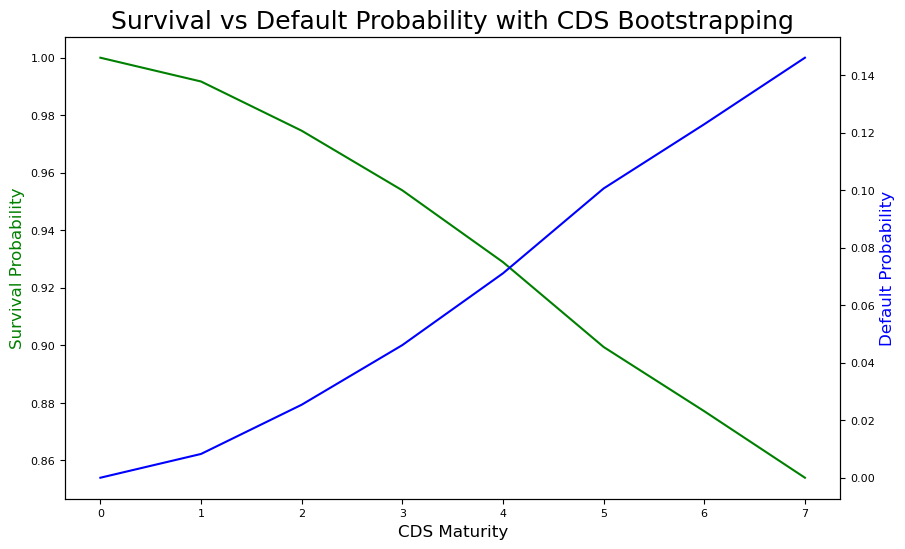

,Maturity,Df,Spread,dt,Survival,Hazard,Default
0,0,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,1,0.9700,0.0050,1.0000,0.9917,0.0083,0.0083
2,2,0.9400,0.0077,1.0000,0.9746,0.0174,0.0254
3,3,0.9200,0.0094,1.0000,0.9539,0.0215,0.0461
4,4,0.8895,0.0109,1.0000,0.9289,0.0265,0.0711
5,5,0.8600,0.0125,1.0000,0.8994,0.0323,0.1006
6,6,0.8346,0.0129,1.0000,0.8771,0.0251,0.1229
7,7,0.8100,0.0133,1.0000,0.8540,0.0267,0.1460


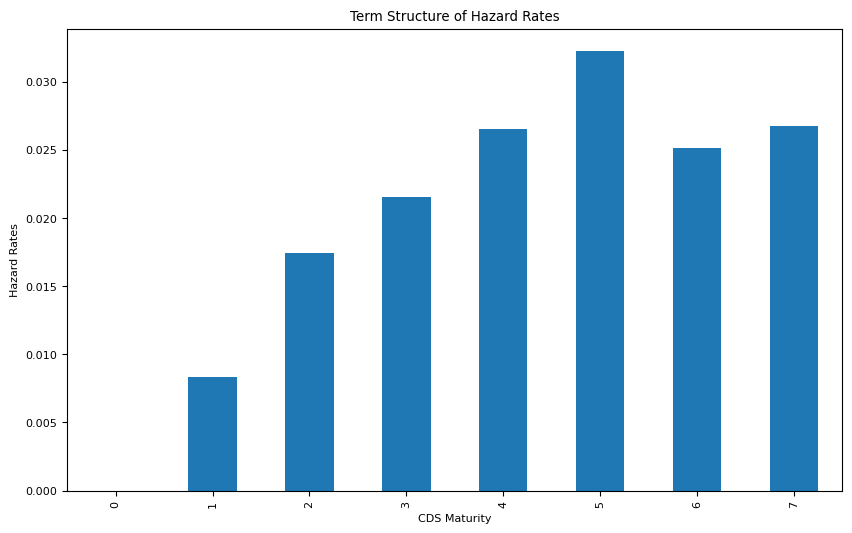

In [22]:
WFC = survival_probability(df.Maturity,df.Df,df.WFC,0.50,plot_prob=True,plot_hazard=True)
WFC

### Survival Probability with Recovery Rates

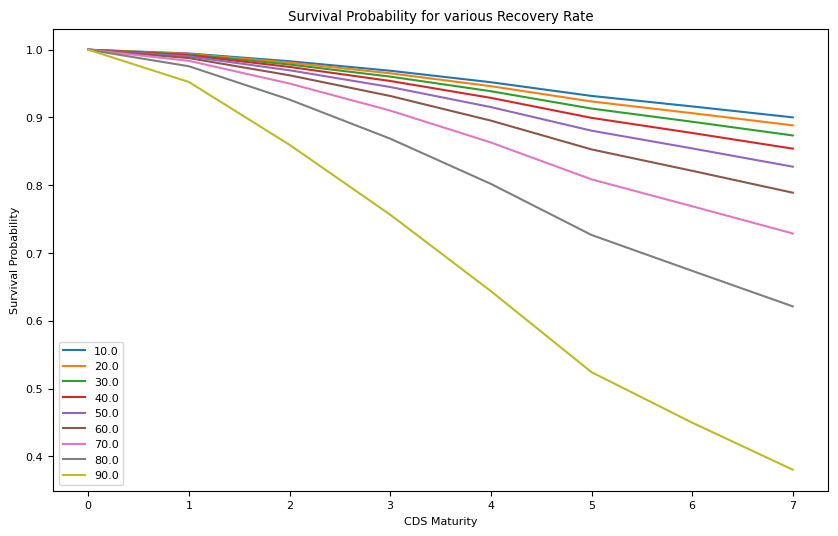

In [40]:
sp = pd.DataFrame()

for recovery_rate in np.arange(0.1,1,0.1):
    sp[recovery_rate] = survival_probability(df.Maturity,df.Df,df.WFC,recovery_rate)['Survival']
    
sp.columns = np.around(sp.columns*100,decimals = 0)
sp.plot()
plt.legend()
plt.title('Survival Probability for various Recovery Rate')
plt.xlabel('CDS Maturity')
plt.ylabel('Survival Probability')
plt.show()

### Credit Triangle Principle

The low levels of recovery rates have almost no effect on the shape of the survival probability curve, while the high levels induce a skew. The relationship between credit spreads, hazard rates, and recovery rates is also approximated using the **Credit Triangle Principle CDS = λ * (1 − R)** that applies over small timescale.

this means that **if we increase recovery rate then implied hazard rate will need to increase accordingly because CDS spread is coming from market.**

### Hazard Rates with Recovery Rates

In [44]:
hr = pd.DataFrame()

for recovery_rate in np.arange(0.1,1,0.1):
    hr[recovery_rate] = survival_probability(df.Maturity,df.Df,df.WFC,recovery_rate)['Hazard']
    

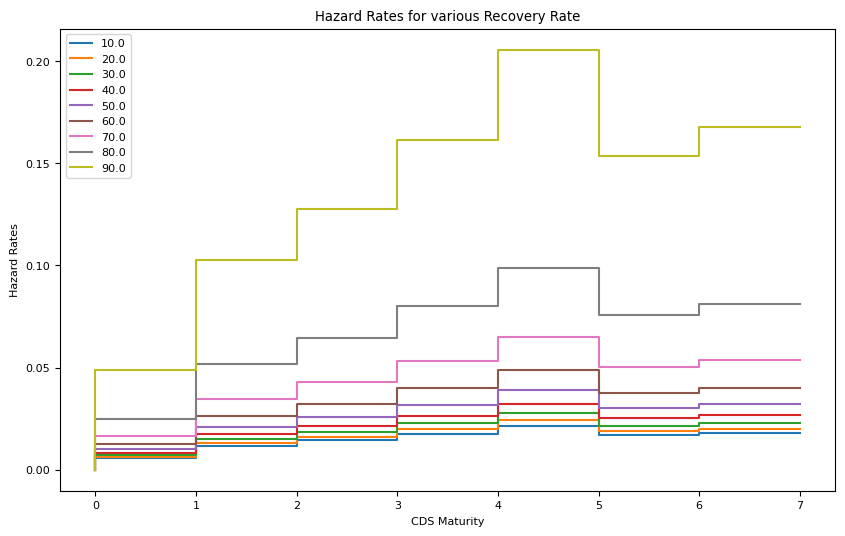

In [50]:
hr = pd.DataFrame()

for recovery_rate in np.arange(0.1,1,0.1):
    hr[recovery_rate] = survival_probability(df.Maturity,df.Df,df.WFC,recovery_rate)['Hazard']
    plt.step(x = hr.index, y = hr[recovery_rate],where = 'pre',label=np.around(recovery_rate*100) )

plt.legend()
plt.title('Hazard Rates for various Recovery Rate')
plt.xlabel('CDS Maturity')
plt.ylabel('Hazard Rates')
plt.show()

# B. Quantlib Implementation

Given the maturity and market quoted spreads, we'll now derive the hazard rates and survival probability using QuantLib-Python and compare the result with the one derived above. For this exercise, we'll use the Trans-European Automated Real-time Gross settlement Express Transfer (TARGET) calendar. Further, we'll reprice the quoted CDS spreads employed for calibration and verify the outcome.

In [53]:
# inputs
maturity = np.arange(6)
discountfactor = [0, 0.97, 0.94, 0.92, 0.89, 0.86]
cds_spread = [0, 50, 77, 94, 109.5, 125]
recovery = 0.40

sp = survival_probability(maturity,discountfactor,cds_spread,recovery)
sp

,Maturity,Df,Spread,dt,Survival,Hazard,Default
0,0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,1,0.9700,0.0050,1.0000,0.9917,0.0083,0.0083
2,2,0.9400,0.0077,1.0000,0.9746,0.0174,0.0254
3,3,0.9200,0.0094,1.0000,0.9539,0.0215,0.0461
4,4,0.8900,0.0109,1.0000,0.9289,0.0265,0.0711
5,5,0.8600,0.0125,1.0000,0.8994,0.0323,0.1006


In [151]:
recovery_rate = 0.4

calender = TARGET()                                       # TARGET()
today_date = Date(30,3,2024)                              # Date()
Settings.instance().evaluationDate = today_date           # Settings.instance.evaluationDate

In [152]:
risk_free_rate = YieldTermStructureHandle(FlatForward(today_date, 0.0, 
                                                      Actual365Fixed()))                           # YieldTermStructureHandle()

### Hazard Rate

In [153]:
quoted_spreads = [0.005, 0.0077, 0.0094, 0.01095, 0.0125]

tenors = [Period(1,Years), Period(2,Years), Period(3,Years), Period(4,Years),Period(5,Years)]       # Period()
maturities = [calender.adjust(today_date + x,Following) for x in tenors]                            # calender.adjust()

In [154]:
SpreadCdsHelper(quoted_spreads[1],tenors[1],0,calender,Annual,Following,
                DateGeneration.TwentiethIMM,Actual365Fixed(),recovery_rate,risk_free_rate)   # SpreadCdsHelper()

instruments = [SpreadCdsHelper(s,t,0,calender,Annual,
                               Following,DateGeneration.TwentiethIMM,
                               Actual365Fixed(),
                               recovery_rate,risk_free_rate)
               for s,t in zip(quoted_spreads,tenors)]           

In [155]:
hazard_curve = PiecewiseFlatHazardRate(today_date,instruments,Actual365Fixed())             # PiecewiseFlatHazardRate()

In [156]:
hazard_curve.nodes()                                                                        # hazard_curve.nodes()

((Date(30,3,2024), 0.00827708315391773),
 (Date(20,6,2025), 0.00827708315391773),
 (Date(22,6,2026), 0.018384413911726214),
 (Date(21,6,2027), 0.02214669349100193),
 (Date(20,6,2028), 0.026924145979837482),
 (Date(20,6,2029), 0.03244741762871445))

In [157]:
hazard_curve.survivalProbability(maturities[1])                                             # hazard_curve.survivalProbability()

0.9759042430027892

In [158]:
for counter in range(1,len(maturities)+1):
    print("{}Y survival probability is {}".format(counter,hazard_curve.survivalProbability(maturities[counter-1])))

1Y survival probability is 0.9917345878225664
2Y survival probability is 0.9759042430027892
3Y survival probability is 0.9553555894155954
4Y survival probability is 0.9309188274907956
5Y survival probability is 0.901995854164007


### Reprice Instruments

In [159]:
notional = 1000000

In [165]:
default_probability = DefaultProbabilityTermStructureHandle(hazard_curve)             # DefaultProbabilityTermStructureHandle()

# create a cds for every maturity:
all_cds = []

for maturity,spread in zip(maturities, quoted_spreads):
    schedule = Schedule(today_date,maturity,Period(Annual),calender,Following,        # Schedule()
                        Unadjusted, DateGeneration.TwentiethIMM, False)
    
    cds = CreditDefaultSwap(Protection.Seller,notional,spread,schedule,               # CreditDefaultSwap()
                            Following,Actual365Fixed())
    
    engine = MidPointCdsEngine(default_probability,recovery_rate,risk_free_rate)      # MidPointCdsEngine()
    cds.setPricingEngine(engine)                                                      # setPricingEngine()
    all_cds.append(cds)
    
    
for cds,tenor in zip(all_cds, tenors):
    print("for Tenor {} values are as follows".format(tenor))
    print("    Fair value of spread {:0.6f}".format(cds.fairSpread()))                # fairSpread()
    print("    NPV value is {:0.2f}".format(cds.NPV()))                               # NPV()
    print("    Default Leg value is {:0.2f}".format(cds.defaultLegNPV()))             # defaultLegNPV()
    print("    Premium Leg value is {:0.2f}".format(cds.couponLegNPV()))              # couponLegNPV()

for Tenor 1Y values are as follows
    Fair value of spread 0.004966
    NPV value is 40.81
    Default Leg value is -6010.42
    Premium Leg value is 6051.22
for Tenor 2Y values are as follows
    Fair value of spread 0.007681
    NPV value is 40.80
    Default Leg value is -16830.06
    Premium Leg value is 16870.86
for Tenor 3Y values are as follows
    Fair value of spread 0.009387
    NPV value is 40.80
    Default Leg value is -29590.72
    Premium Leg value is 29631.52
for Tenor 4Y values are as follows
    Fair value of spread 0.010940
    NPV value is 40.79
    Default Leg value is -44776.21
    Premium Leg value is 44817.00
for Tenor 5Y values are as follows
    Fair value of spread 0.012492
    NPV value is 40.79
    Default Leg value is -62501.34
    Premium Leg value is 62542.13


### References

[QuantLib](https://github.com/lballabio)